# Module V (completed): transfer learning with VGG16 and YOLOv8
Two controlled comparisons. Results from `report/syllabus_results/`; analysis in `report/SYLLABUS.md`.

In [1]:
import sys, os, json, inspect
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
import numpy as np, matplotlib.pyplot as plt, matplotlib.image as mpimg
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
res = lambda n: json.load(open(ROOT / "report" / "syllabus_results" / f"{n}.json"))
def show(name, width=15):
    img = mpimg.imread(ROOT / "report" / "figures" / f"syllabus_{name}.png")
    plt.figure(figsize=(width, width * img.shape[0] / img.shape[1])); plt.imshow(img); plt.axis("off"); plt.show()


## VGG16 on partial sketches (image only), against ResNet18 and a small CNN from scratch

In [2]:
from src.syllabus.vgg_transfer import ImageNetBackbone
print(inspect.getsource(ImageNetBackbone))

class ImageNetBackbone(nn.Module):
    """Wraps a torchvision VGG16 or ResNet18: 1-channel 64x64 raster -> class logits."""

    def __init__(self, arch: str, freeze: bool, pretrained: bool = True):
        super().__init__()
        import torchvision

        if arch == "vgg16":
            w = torchvision.models.VGG16_Weights.IMAGENET1K_V1 if pretrained else None
            self.features = torchvision.models.vgg16(weights=w).features              # 64x64 -> 2x2x512
            feat = 512 * 2 * 2
        else:
            w = torchvision.models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
            net = torchvision.models.resnet18(weights=w)
            net.fc = nn.Identity()
            self.features = net
            feat = 512
        self.frozen = freeze
        if freeze:
            for p in self.features.parameters():
                p.requires_grad = False
        self.head = nn.Sequential(nn.Flatten(), nn.Linear(feat, 256), nn.ReLU(inplace=True), nn.Dropout(0.4

Top-5 %                    10%     20%     30%     50%     75%    100%
small CNN (scratch)       74.3    89.2    93.9    96.8    98.3    98.4
vgg16_frozen              65.4    83.7    88.9    92.3    95.3    95.9   (532,254 trained params)
vgg16_finetune            73.8    88.8    93.7    97.0    98.6    98.9   (15,246,942 trained params)
resnet18_finetune         71.7    87.0    92.0    95.7    97.8    98.6   (11,315,550 trained params)


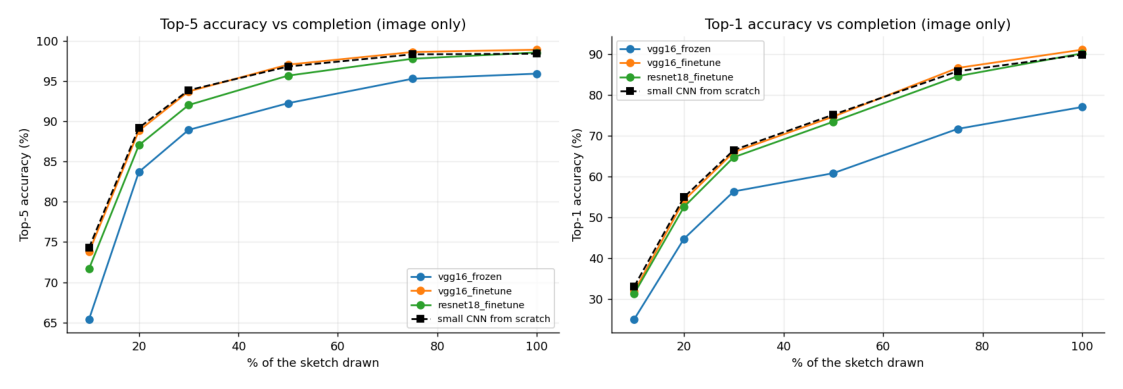

In [3]:
v = res('vgg'); F = ['0.1', '0.2', '0.3', '0.5', '0.75', '1.0']
print(f"{'Top-5 %':<22}" + ''.join(f'{int(float(f)*100):>7}%' for f in F))
print(f"{'small CNN (scratch)':<22}" + ''.join(f"{v['small_cnn_from_scratch'][f]['top5']*100:>8.1f}" for f in F))
for m in v['models']: print(f"{m['name']:<22}" + ''.join(f"{m['by_fraction'][f]['top5']*100:>8.1f}" for f in F) + f"   ({m['trainable_params']:,} trained params)")
show('vgg', 13)

## YOLOv8n: COCO-pretrained against random initialisation, on the digit scenes
Same architecture, data, epochs and metric; the only difference is the starting weights. Our from-scratch detector is included for reference.

detector                      mAP@0.5  mAP@.5:.95
YoloLite (ours)                 99.31       94.10
YOLOv8n scratch                 99.39       92.69
YOLOv8n pretrained              99.59       94.41


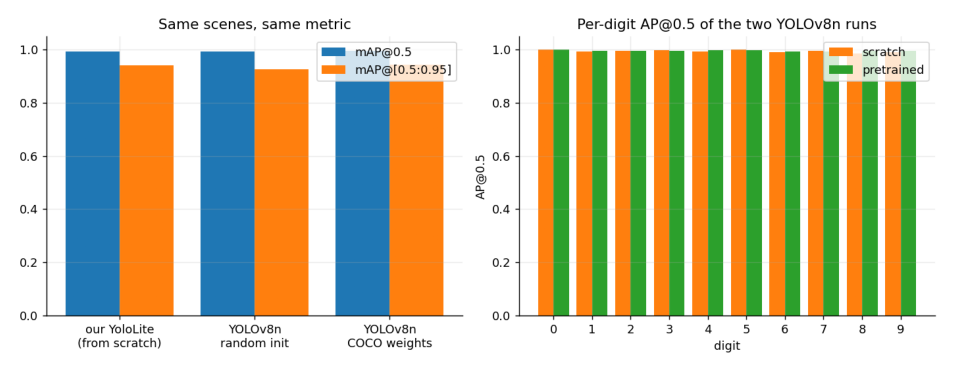

In [4]:
y = res('det_yolov8'); s = res('det_scratch')
print(f"{'detector':<28}{'mAP@0.5':>9}{'mAP@.5:.95':>12}")
print(f"{'YoloLite (ours)':<28}{s['map50']*100:>9.2f}{s['map50_95']*100:>12.2f}")
for m in ('scratch', 'pretrained'): print(f"{'YOLOv8n ' + m:<28}{y[m]['map50']*100:>9.2f}{y[m]['map50_95']*100:>12.2f}")
show('det_yolov8', 11)